# Metadata file summarization

Associated metadata for the raw files was captured comprehensively and on multiple levels.
- Sample metatadata files for each lab (SDRF)
- CellenIon metadata files from dispensing the cells (Reordered_*_isolated.xls)

Here, all metadata files are combined together into a single, comprehensive metadata file to be loaded during exploration and downstream analyses.

## 1. Metadata file construction

In [33]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import pandas as pd
import numpy as np
import os

from glob import glob

from SCI_py.metadata import read as SCI_read
from SCI_py.metadata import parse as SCI_parse
from SCI_py.plot.constants import CONDITION_COLORS, LAB_COLORS

In [34]:
# Set the paths
root_metadata = '/public/conode53/sam/SCI_paper/metadata'
cellenone_root = '/public/conode53/sam/SCI_paper/cellenONE/cellenONE_Reports'

# Read the SDRF files and parse some columns
sdrf = SCI_read.read_SDRF(
    root_metadata
)
# Read the cellenONE metadata files
isolated_df = SCI_read.read_cellenONE(cellenone_root)

# Merge the two metadata sources
metadata = sdrf.merge(
    isolated_df,
    on=['comment[X position]', 'comment[Y position]', 'comment[Plate Number]'],
    how='left'
)

# Add annotations from the plate preparation documentation
metadata = SCI_read.add_docx_annotations(metadata)

# Parse
metadata = SCI_parse.parse_metadata_columns(metadata)

/home/sam/SCI/SCI/SCI_py/SCI_py/metadata/parse.py:135: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(_plate_order))


# Visualization

In [40]:
from SCI_py.plot.metadata import plot_metadata_overview, plot_cell_qc_overview

/home/sam/SCI/SCI/SCI_py/SCI_py/plot/metadata.py:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(plate_order, rotation=45, ha='right')
/home/sam/SCI/SCI/SCI_py/SCI_py/plot/metadata.py:87: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(instrument_counts.index, rotation=35, ha='right')
/home/sam/SCI/SCI/SCI_py/SCI_py/plot/metadata.py:139: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


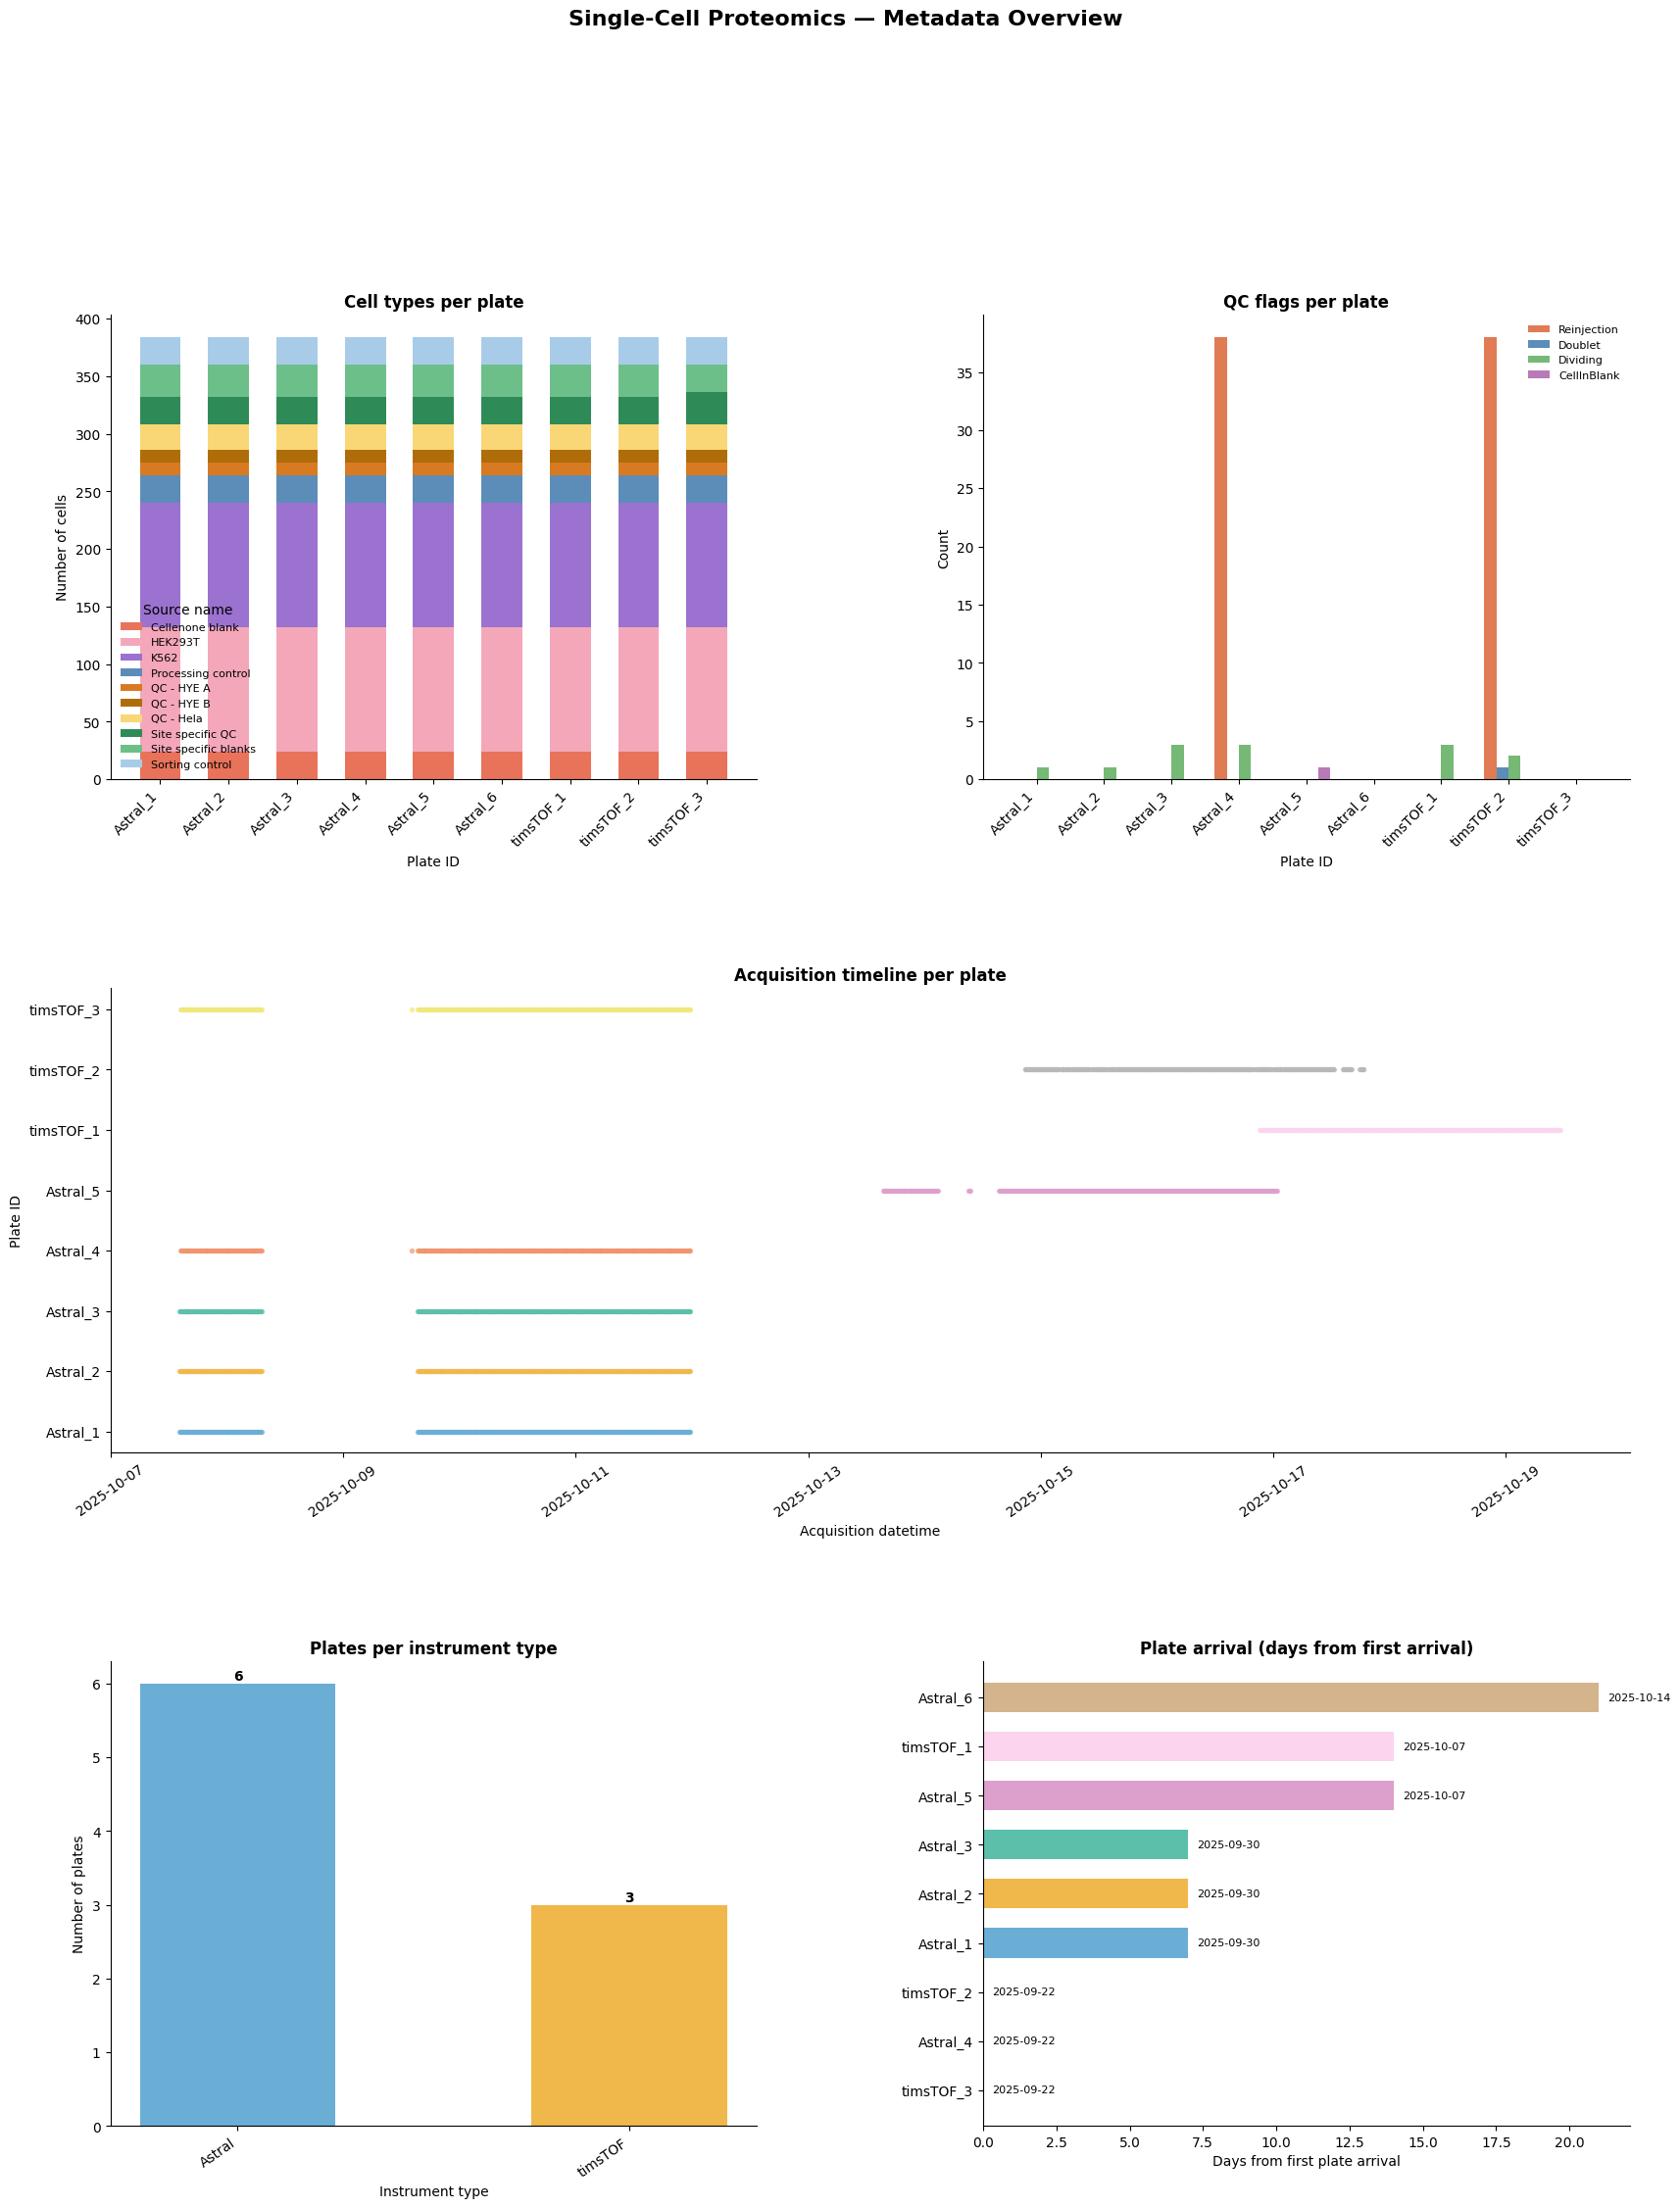

In [41]:
fig = plot_metadata_overview(
    metadata,
    save_path=False
)

K562: 8 valid plates
  x_pos: [-0.2  0.8  1.8  2.8  3.8  4.8  5.8  6.8]
  group sizes: [108, 108, 108, 108, 108, 108, 108, 108]
HEK293T: 8 valid plates
  x_pos: [0.2 1.2 2.2 3.2 4.2 5.2 6.2 7.2]
  group sizes: [108, 100, 108, 108, 108, 108, 108, 108]


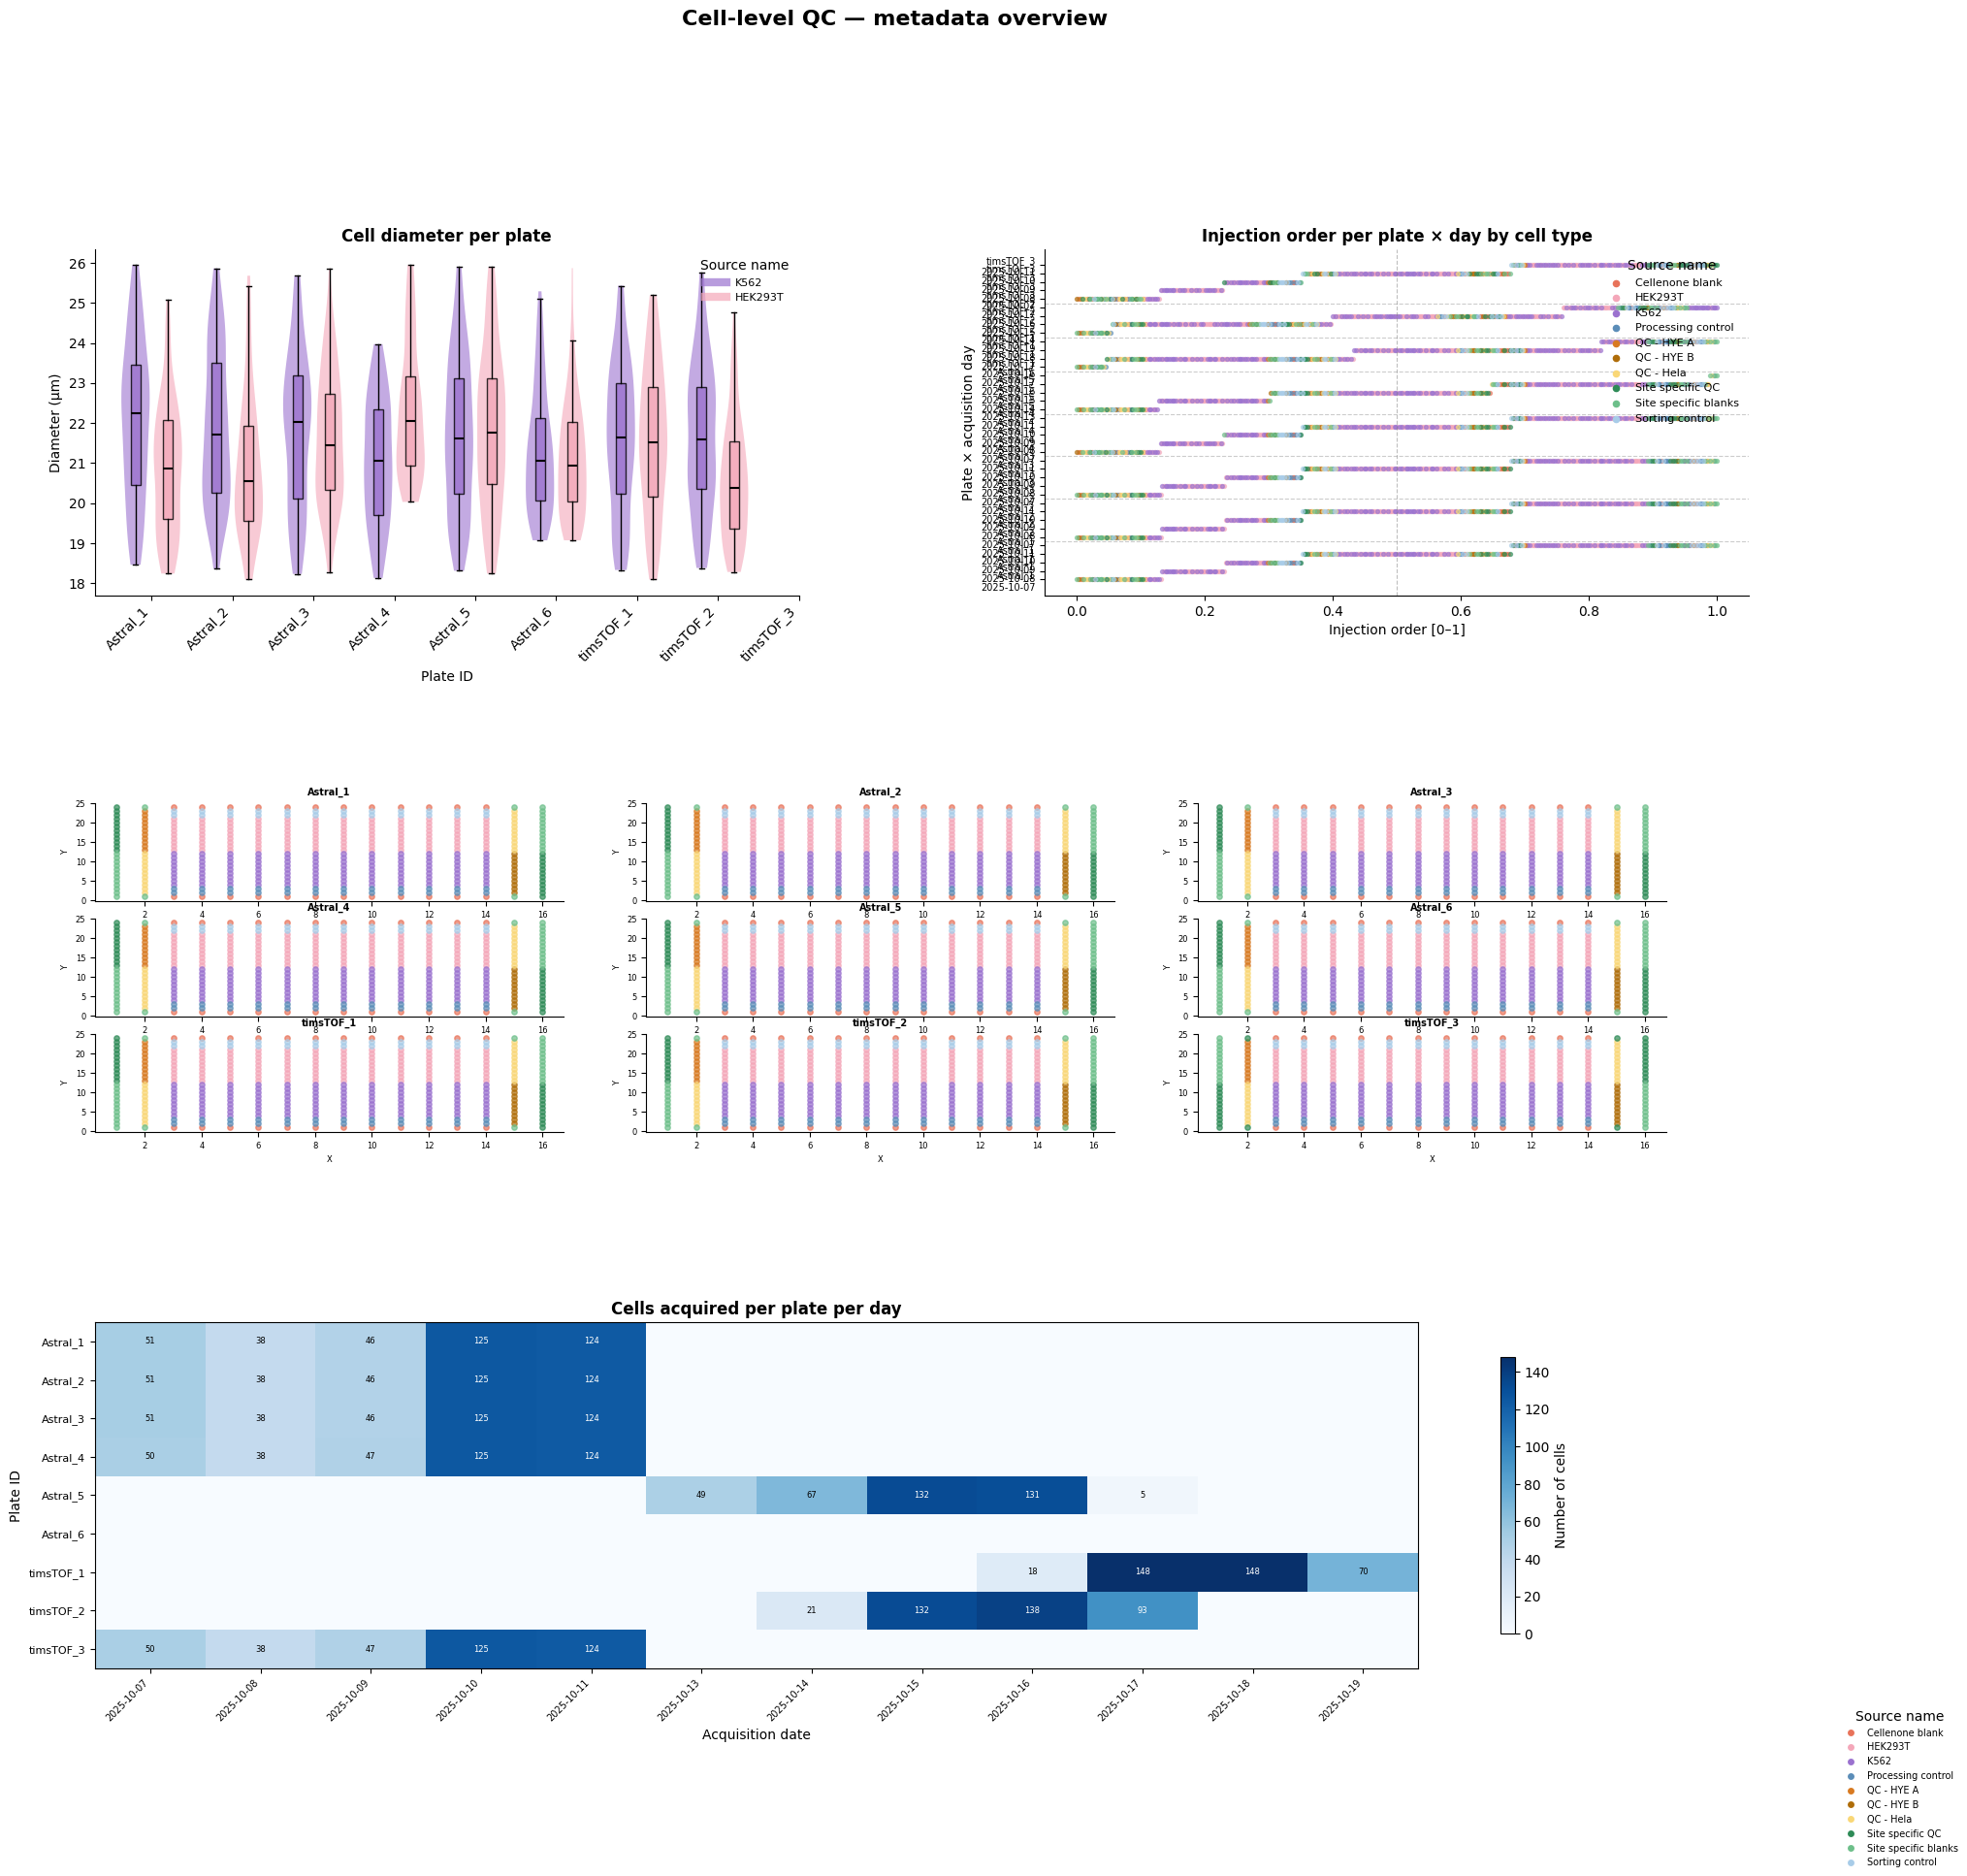

In [42]:
fig = plot_cell_qc_overview(
    metadata, 
    save_path=False
)